# Project title: Melbourne Housing Problem

Dataset source: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

## 1. Introduction & Research Questions


**Motivation**

The Melbourne housing market is one of Australia’s most competitive real estate environments. For buyers trying to find value and sellers trying to price competitively/correctly, understanding what actually drives property prices is crucial to making smart financial decisions. However, property desirability is difficult to quantify, with many factors like location, size, amenities and timing all playing a role. 


**Main Research Question**

"What makes a property desirable in Melbourne's housing market?"

**Objective**

We aim to produce a desirability score which helps to rank the desirability of a property relative to its suburb.  

To achieve this, We first explore the correlations of features and variables in the dataset against price in our EDA through the following research questions:

1. Does distance from the CBD affect property price in Melbourne, and does this vary by house type, region and suburb?
2. How does a property’s total amenity score (bathroom + car spaces) affect price, beyond what is already explained by room count and distance from the CBD, and does this vary by property type?
3. How do total room count and building area, individually and in combination affect property price? Does room density (rooms per square metre) or outside space ratio (land size relative to building area) add further explanatory value?
4. How does the method of sale affect desirability and hence sale price of a property?

This should provide useful insights for buyers to identify properties worth purchasing and sellers to price their properties more competitively.

## 2. Data Dictionary

**Melbourne Housing Dataset Description:**


| Column | Type | Description |
|---|---|---|
| `Suburb` | object | Suburb the property is located in |
| `Address` | object | Street address — includes unit number for townhouses and apartments |
| `Rooms` | int | Number of rooms *(landed houses only)* |
| `Type` | object | Property type — `h` = landed house · `t` = townhouse · `u` = apartment |
| `Price` | float | Sale price in AUD |
| `Method` | object | Sale outcome — `S` = sold · `SP` = sold prior · `VB` = vendor bid · `PI` = passed in |
| `SellerG` | object | Name of the listing real estate agency |
| `Date` | object | Date of sale |
| `Distance` | float | Distance from CBD in km *(landed houses only)* |
| `Postcode` | float | Postcode of the property |
| `Bedroom2` | float | Bedroom count scraped from a secondary source — cross-check against `Rooms` |
| `Bathroom` | float | Number of bathrooms |
| `Car` | float | Number of car parking spots tied to the property |
| `Landsize` | float | Land area in m² *(landed houses only)* |
| `BuildingArea` | float | Built structure area in m² |
| `YearBuilt` | float | Year the property was originally constructed |
| `CouncilArea` | object | Local governing council the property falls under |
| `Lattitude` | float | Latitude coordinate |
| `Longtitude` | float | Longitude coordinate |
| `Regionname` | object | Broad metro region — e.g. *Northern Metropolitan*, *South-Eastern Metropolitan* |
| `Propertycount` | float | Total number of properties in the suburb |

> **Heads up on data quality**
> - `Distance`, `Rooms`, and `Landsize` are populated *only for landed houses* — expect nulls for townhouses and units
> - `BuildingArea` and `YearBuilt` have significant missingness (~47% and ~40% respectively)
> - `Bedroom2` is a secondary scrape and may conflict with `Rooms` — treat with caution and prefer `Rooms`
> - `Landsize` contains 1,939 zeros and extreme outliers — likely data entry errors, not true values

## 3. Executive Summary

Identified room count, total amenities, and property type as the strongest predictors of sale price. 

These features were used to construct a suburb-relative desirability score (0 to 100) that ranks each property against others within the same suburb, achieving a correlation of 0.53 with price. 

A linear regression on the score produced an R² of 0.28 city-wide, improving to between 0.68 and 0.74 at the suburb level, confirming the score is most reliable as a local market comparison tool. Key limitations include the dataset covering only 2016 to 2018 and the absence of features such as proximity to schools, public transport, and crime statistics, which future iterations should incorporate.

## 4. Data Loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error
import random

sns.set_style('dark')

In [2]:
# Load the dataset
df = pd.read_csv('melb_data.csv')

# First look at data
print('Shape:')
print(df.shape)

print('\nColumn types:')
print(df.dtypes)

print('\nMissing data:')
print(df.isna().sum())

print('\nFirst five rows:')
print(df.head())

print('\nNumeric summary:')
print(df.describe().round(2))

Shape:
(5, 4)

Column types:
Evaluation Metric    object
Melbourne            object
Suburb 1             object
Suburb 2             object
dtype: object

Missing data:
Evaluation Metric    0
Melbourne            0
Suburb 1             0
Suburb 2             0
dtype: int64

First five rows:
         Evaluation Metric      Melbourne       Suburb 1       Suburb 2
0                 R Square         0.2831         0.6832         0.7414
1      Mean Absolute Error   $367,008.00    $327,583.00    $220,972.00 
2  Root Mean Squared Error   $554,105.00    $425,171.00    $292,918.00 
3              Coefficient     13,785.00      26,779.00      16,899.00 
4                Intercept    282,716.00    (170,433.00)     48,054.00 

Numeric summary:
       Evaluation Metric Melbourne Suburb 1 Suburb 2
count                  5         5        5        5
unique                 5         5        5        5
top             R Square    0.2831   0.6832   0.7414
freq                   1         1        1  

**We note the following:**

* `BuildingArea` and `YearBuilt` have significant missing values (>40%).
* Some missing values in `CouncilArea` and `Cars`.
* `Price` ranges from \\$85,000 to $9,000,000 with a mean well above the median which suggest a right skew to the prices.


## 5. Data Cleaning

In [3]:
#-----Data Cleaning-----#

# Dropping duplicated rows
df = df.drop_duplicates()

# Dropping cols with low signal strength
df = df.drop(columns=['Address', 'Bedroom2', 'Postcode', 'Longtitude', 'Lattitude', 'CouncilArea'])
print(f"Columns remaining: {df.columns.tolist()}\n")

# Convert 'Date' to datetime
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Replace Landsize and BuildingArea zeros and NaaN
df['Landsize']     = df['Landsize'].replace(0, np.nan)
df['BuildingArea'] = df['BuildingArea'].replace(0, np.nan)
print(f"Landsize nulls after zero-fill:      {df['Landsize'].isna().sum()}")
print(f"BuildingArea nulls after zero-fill:  {df['BuildingArea'].isna().sum()}\n")

# Standardizing data types
df['Bathroom'] = df['Bathroom'].astype('Int64')
df['Car'] = df['Car'].astype('Int64')
df['YearBuilt'] = df['YearBuilt'].astype('Int64')
df['Propertycount'] = df['Propertycount'].astype('Int64')

# Convert Bathrooms with 0 value to 1
df.loc[df['Bathroom'] == 0, 'Bathroom'] = 1

#-----Final Look-----#
print("Final shape:\n")
print(df.shape)
print("Dtypes:\n")
print(df.dtypes)
print("Numeric summary\n")
print(df.describe().round(2))

Columns remaining: ['Suburb', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Distance', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Regionname', 'Propertycount']

Landsize nulls after zero-fill:      1939
BuildingArea nulls after zero-fill:  6467

Final shape:

(13580, 15)
Dtypes:

Suburb                   object
Rooms                     int64
Type                     object
Price                     int64
Method                   object
SellerG                  object
Date             datetime64[ns]
Distance                float64
Bathroom                  Int64
Car                       Int64
Landsize                float64
BuildingArea            float64
YearBuilt                 Int64
Regionname               object
Propertycount             Int64
dtype: object
Numeric summary

          Rooms       Price                           Date  Distance  \
count  13580.00    13580.00                          13580  13580.00   
mean       2.94  1075684.08  2017-01

**Rationale:**

* Dropped `Address`,`Longtitude`, `Lattitude`, `Postcode` and `CouncilArea` as these location features are already captured later on in our analysis by categorisation by suburb.
* Dropped `Bedroom2` due to a high correlation with `Rooms` making this feature redundant.
* Converted `Bathroom` values which are 0 to 1, as we found out from the main dataset that these values represent shared houses. 

## 6. Preprocessing

In [3]:
# Is_house = Type == 'h' — houses vs. units/townhouses is one of the strongest price drivers in Melbourne
df['Is_House'] = (df['Type'] == 'h').astype(int)
 
# A unit close to CBD vs. a house far out behave very differently
df['Type_x_Distance'] = df['Is_House'] * df['Distance']
 
# Type_x_Rooms — room count means different things for a townhouse vs. a house
df['Type_x_Rooms'] = df['Is_House'] * df['Rooms']
 

print(df[['Type', 'Is_House', 'Distance', 'Type_x_Distance',
          'Rooms', 'Type_x_Rooms']].head(10).to_string(index=False))

KeyError: 'Type'

In [5]:
# Encoding categorical variable: Type
# 'Type' column contains string values ('h', 't', 'u')
# Encoded into binary Is_House (1 = house, 0 = unit/townhouse)
df['Is_House'] = (df['Type'] == 'h').astype(int)

# MinMax Scaling (0–100) applied to continuous features:
# - Distance to Score_Proximity (inverted so closer to CBD = higher score)
# - Type_x_Rooms to Score_Rooms

scaler_mm = MinMaxScaler(feature_range=(0, 100))
df['Score_Proximity'] = 100 - scaler_mm.fit_transform(df[['Distance']]).flatten()
df['Score_Rooms'] = scaler_mm.fit_transform(df[['Type_x_Rooms']]).flatten()

# Manual encoding for house type rank
TYPE_SCORE = {'h': 100, 't': 80, 'u': 50}
df['Score_HouseType'] = df['Type'].map(TYPE_SCORE)

## 7. Feature Engineering

**Price-relevant features**

* Price_per_room = Price / Rooms — normalises price by size, useful for comparing value

**Size & capacity features**

* Total_amenities = Bathroom + Car — a single "liveability" score
* Bedroom_bathroom_ratio = Bedroom2 / Bathroom — imbalanced ratios can suppress price

**Age & time features**

* Sale_year, Sale_month, Sale_quarter extracted from Date — Melbourne's property market has strong seasonality

**Location features**

* Distance_band = bin Distance into Inner, Middle and Outer (0–5km, 5–10km, etc.) for a categorical distance zone
* Suburb_median_price - Group by suburb and compute the median price 

**Property type interactions**

* Is_house = Type == 'h' — houses vs. units/townhouses is one of the strongest price drivers in Melbourne
* Type_x_Distance — interaction term; a unit close to CBD vs. a house far out behave very differently
* Type_x_Rooms — room count means different things for a townhouse vs. a house

**Agent / market features**

* Agent_avg_price = SellerG grouped by median sale price — premium agents tend to list premium properties; could be a proxy for listing quality
* Sale_method_binary — simplify Method into Sold = S or SP vs. Not sold = VB or PI; whether a property actually sold is signal


In [6]:
df_2 = df

# Age & Time Features
df_2['Sale_year']       = df_2['Date'].dt.year
df_2['Sale_month']      = df_2['Date'].dt.month
df_2['Sale_quarter']    = df_2['Date'].dt.quarter

# Price-Relevant Ratios (for analysis only)
df_2['Price_per_room']         = df_2['Price'] / df_2['Rooms']

# Size & Capacity Features
df_2['Total_amenities']       = df_2['Bathroom'].astype(float) + df_2['Car'].astype(float)
df_2['Bedroom_bathroom_ratio']= df_2['Rooms'] / df_2['Bathroom'].astype(float)

# Location Features
df_2['Is_inner_city']  = (df_2['Distance'] < 10).astype(int)
df_2['Distance_band']  = pd.cut(
    df_2['Distance'],
    bins=[0, 5, 10, 15, 20, 30, 50, 100],
    labels=['0-5', '5-10', '10-15', '15-20', '20-30', '30-50', '50+']
)

suburb_median = df_2.groupby('Suburb')['Price'].median()
df_2['Suburb_median_price']  = df_2['Suburb'].map(suburb_median)
suburb_avg_land = df_2.groupby('Suburb')['Landsize'].mean()
df_2['Suburb_avg_landsize']  = df_2['Suburb'].map(suburb_avg_land)

# Property Type Features
df_2['Is_house']       = (df_2['Type'] == 'h').astype(int)
df_2['Type_x_Distance']= df_2['Is_house'] * df_2['Distance']
df_2['Type_x_Rooms']   = df_2['Is_house'] * df_2['Rooms']

# Agent / Market Features
agent_med = df_2.groupby('SellerG')['Price'].median()
df_2['Agent_avg_price']     = df_2['SellerG'].map(agent_med)
df_2['Sale_method_binary']  = df_2['Method'].isin(['S', 'SP']).astype(int)

print(f'Total features after engineering: {df_2.shape[1]}')
print(df_2.shape)

Total features after engineering: 34
(13580, 34)


## 8. Preliminary Analysis / Exploratory Data Analysis (EDA) 

### Correlation of housing features heatmap

In [4]:
# General Heatmap for exploratory analysis
cols=['Suburb','Rooms','Type','Price','Method','SellerG','Date','Bathroom','Car','Landsize','BuildingArea','YearBuilt','Regionname','Propertycount']
original_df=df[cols]
num_house = original_df.select_dtypes(include='number')

# Print heatmap
corr = num_house.corr()
sns.heatmap(corr, annot=True, center=0, square=True, linewidths=0.2);
plt.title('Correlation of housing features');

KeyError: "None of [Index(['Suburb', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date',\n       'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt',\n       'Regionname', 'Propertycount'],\n      dtype='object')] are in the [columns]"

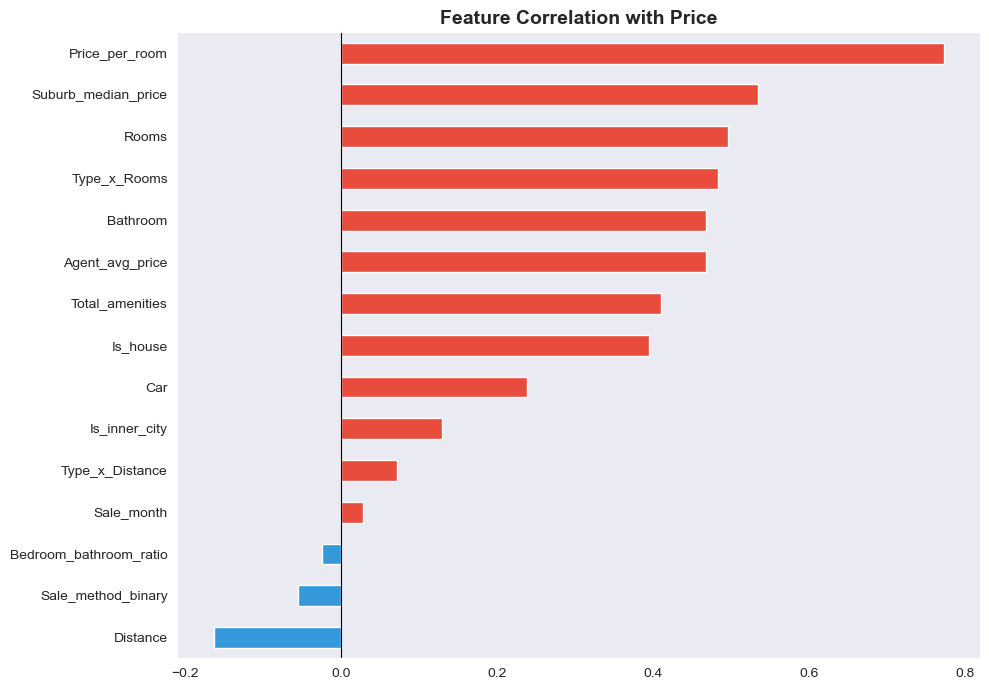


Top 10 correlated features:
Price_per_room         0.7724
Suburb_median_price    0.5348
Rooms                  0.4966
Type_x_Rooms           0.4834
Bathroom               0.4686
Agent_avg_price        0.4681
Total_amenities        0.4098
Is_house               0.3950
Car                    0.2390
Is_inner_city          0.1297


In [8]:
feature_cols = [
    'Rooms', 'Distance', 'Bathroom', 'Car', 'Price_per_room', 'Total_amenities', 'Bedroom_bathroom_ratio',
    'Is_inner_city', 'Is_house', 'Type_x_Distance', 'Type_x_Rooms',
    'Agent_avg_price', 'Sale_method_binary', 'Sale_month',
    'Suburb_median_price'
]

corr_with_price = (
    df_2[feature_cols + ['Price']].corr()['Price']
    .drop('Price')
    .sort_values(ascending=False)
)

# Plot 
fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#e74c3c' if v >= 0 else '#3498db' for v in corr_with_price]
corr_with_price.plot(kind='barh', ax=ax, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Feature Correlation with Price', fontsize=14, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print('\nTop 10 correlated features:')
print(corr_with_price.head(10).round(4).to_string())

### 1. Total amenities
We investigated the corelation between Price and Total amenities.

Text(0.5, 1.0, 'Price vs Total Amenities')

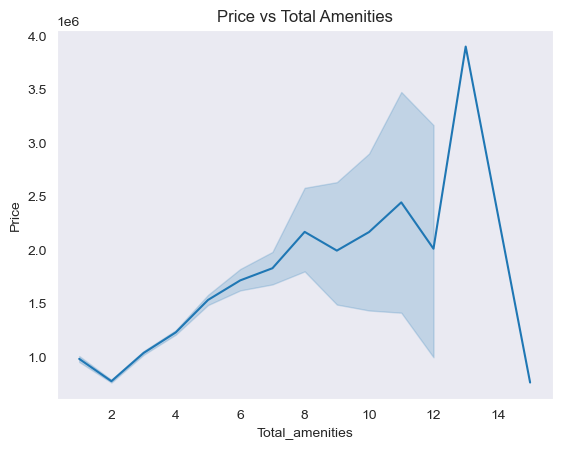

In [9]:
sns.lineplot(data=df_2, x='Total_amenities', y='Price' )
plt.title('Price vs Total Amenities')

Text(0.5, 1.0, 'Price vs Total Amenities')

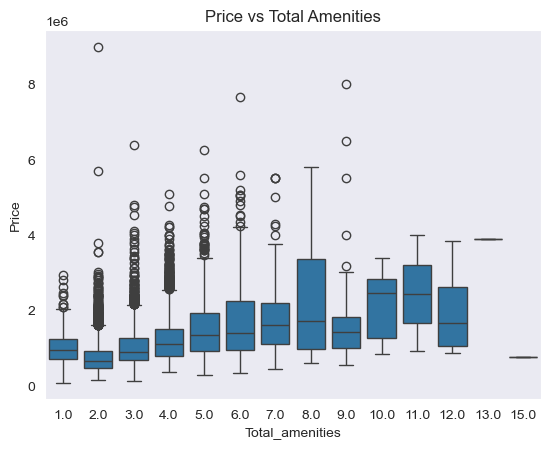

In [10]:
sns.boxplot(data=df_2, x='Total_amenities', y='Price' )
plt.title('Price vs Total Amenities')

**Key observations:**
- Median price generally increases as total amenity count increases
- Smaller sample size of higher total amenity counts resulted in greater variance of median prices

### 2. Type x Distance
We investigated the correlation between Type x distance and Price.

Text(0, 0.5, 'Price ($)')

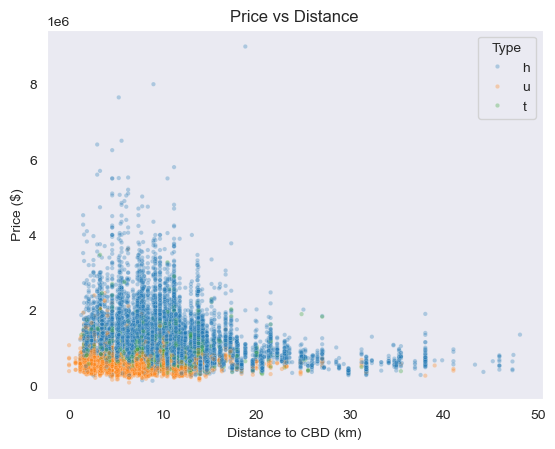

In [11]:
sns.scatterplot(data=df, x='Distance', y='Price', hue='Type', alpha=0.3, s=10)
plt.title('Price vs Distance')
plt.xlabel('Distance to CBD (km)')
plt.ylabel('Price ($)')

**Key observations:**
- Houses have the widest price range and is highest across all distances. Prices peak within 10km of the CBD and drop off beyond that.
- Townhouses and units mainly stays at the bottom of the scatterplot regardless of distance. This shows that the price for these property types are largely unaffected by their distance from CBD.

This confirms that Type_x_Distance is valid, as distance mainly affects "House" prices, not "Units" or "Townhouses".

### 3. Investigate the median price of properties by property type

In [12]:
df_4=df.groupby('Type')['Price'].median()
print(df_4)


Type
h    1080000.0
t     846750.0
u     560000.0
Name: Price, dtype: float64


**Key observations:**
- We see that houses commands an estimated 27.5% increase in prices over town houses.
- Town houses commands an estimated 50% increase in price over units. 


### 4. Investigate the median price by number of rooms and property type

In [13]:
df["Type_Label"] = df["Type"].map({
    "h": "House",
    "t": "Townhouse",
    "u": "Unit"
})

rooms_type_summary = df.groupby(["Type_Label", "Rooms"])["Price"].agg(
    count="count",
    median_price="median",
    mean_price="mean"
).reset_index()

print(rooms_type_summary)

   Type_Label  Rooms  count  median_price    mean_price
0       House      1     58      857500.0  8.668655e+05
1       House      2   1398      950000.0  1.017238e+06
2       House      3   4801      990000.0  1.109233e+06
3       House      4   2517     1300000.0  1.462283e+06
4       House      5    591     1670000.0  1.877327e+06
5       House      6     66     1820000.0  1.869508e+06
6       House      7     10     1496000.0  1.920700e+06
7       House      8      7     1150000.0  1.510286e+06
8       House     10      1      900000.0  9.000000e+05
9   Townhouse      1     11      580000.0  5.927045e+05
10  Townhouse      2    319      675000.0  7.101585e+05
11  Townhouse      3    629      900000.0  9.847087e+05
12  Townhouse      4    150     1157500.0  1.217092e+06
13  Townhouse      5      5     1000000.0  1.035000e+06
14       Unit      1    612      377500.0  3.899289e+05
15       Unit      2   1931      585000.0  6.104905e+05
16       Unit      3    451      780000.0  8.505

In [14]:
rooms_type_pivot=rooms_type_summary.pivot(index="Rooms",columns="Type_Label",values="median_price")
print(rooms_type_pivot)

Type_Label      House  Townhouse       Unit
Rooms                                      
1            857500.0   580000.0   377500.0
2            950000.0   675000.0   585000.0
3            990000.0   900000.0   780000.0
4           1300000.0  1157500.0   830000.0
5           1670000.0  1000000.0        NaN
6           1820000.0        NaN   520000.0
7           1496000.0        NaN        NaN
8           1150000.0        NaN  2250000.0
10           900000.0        NaN        NaN


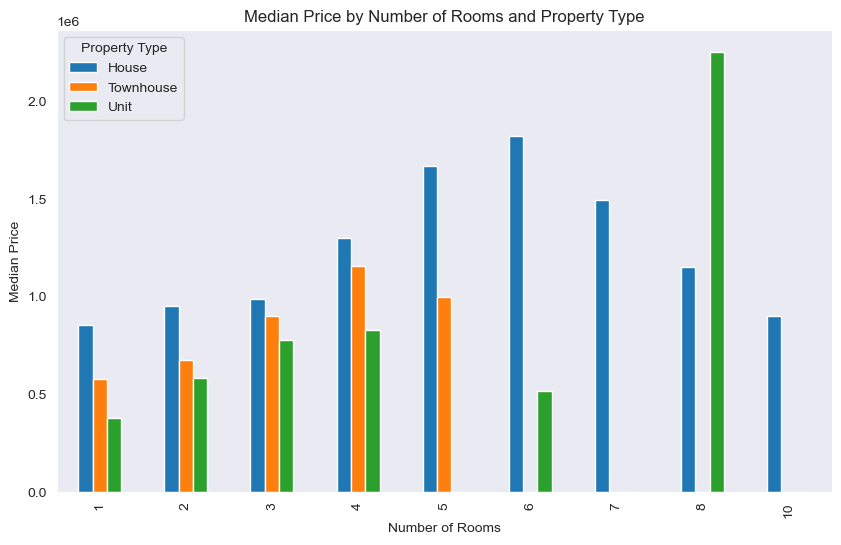

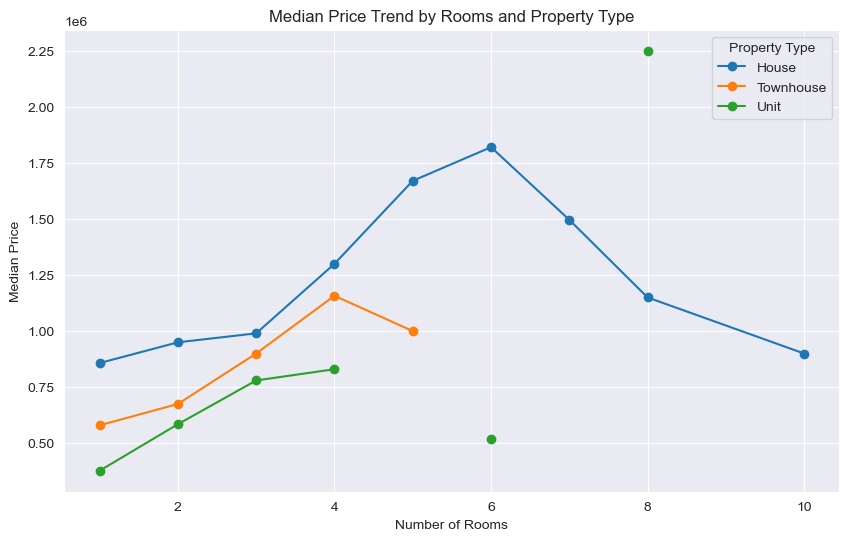

Correlation between Rooms and Price: 0.497


In [15]:
rooms_type_pivot.plot(kind="bar", figsize=(10, 6))

plt.title("Median Price by Number of Rooms and Property Type")
plt.xlabel("Number of Rooms")
plt.ylabel("Median Price")
plt.legend(title="Property Type")
plt.show()

rooms_type_pivot.plot(kind="line", marker="o", figsize=(10, 6))

plt.title("Median Price Trend by Rooms and Property Type")
plt.xlabel("Number of Rooms")
plt.ylabel("Median Price")
plt.legend(title="Property Type")
plt.grid(True)
plt.show()

print("Correlation between Rooms and Price:", round(df["Rooms"].corr(df["Price"]), 3))

**Key observations:**
- The median price generally increases as the number of rooms increases
- "House" type shows the strongest increase in median price

This tells us that using 'Is_house' with 'Rooms' is justified, as it captures the additional market value associated with houses that is not fully explained by room alone, suggesting that room count is valued differently depending on property type.

### 5. Method Effect on Sale Price

#### Considerations

**What is `Method`?**  
The `Method` column records the mechanism by which each property was sold at auction or negotiation:

| Code | Description |
|------|-------------|
| **S** | Property sold at auction |
| **SP** | Property sold prior to auction |
| **PI** | Property passed in (reserve not met) |
| **VB** | Vendor bid placed at auction |

> `SA` (Sold after auction) has been excluded — with only ~41 records after cleaning, it is statistically insignificant and risks introducing noise into the model.

In [16]:
# ── Filter to four meaningful methods ─────────────────────────────────────
# BuildingArea & Bedroom2 excluded (data loss / multicollinearity — see rationale above)
# Landsize excluded: high NA count; remaining NAs in Car/YearBuilt imputed to preserve rows
METHODS = ['S', 'SP', 'PI', 'VB']
BASELINE = 'S'

model_cols = ['Price', 'Method', 'Rooms', 'Distance', 'Bathroom', 'Car', 'YearBuilt']

df_model = df[model_cols].query('Method in @METHODS').copy()
df_model['YearBuilt'] = df_model['YearBuilt'].fillna(df_model['YearBuilt'].median())
df_model['Car'] = df_model['Car'].fillna(0)

print(f'Rows used for modelling: {len(df_model)}')
print('\nMethod distribution:')
print(df_model['Method'].value_counts())

# ── One-Hot Encode Method (baseline = 'S') ────────────────────────────────
ohe = OneHotEncoder(drop=[BASELINE], sparse_output=False)
method_encoded = ohe.fit_transform(df_model[['Method']])
method_dummy_cols = ohe.get_feature_names_out(['Method'])

print(f'\nBaseline (dropped): {BASELINE}')
print(f'Dummy columns created: {list(method_dummy_cols)}')

# ── Build feature matrix ──────────────────────────────────────────────────
numeric_features = ['Rooms', 'Distance', 'Bathroom', 'Car', 'YearBuilt']
X = np.hstack([df_model[numeric_features].values.astype(float), method_encoded])
feature_names = numeric_features + list(method_dummy_cols)
y = df_model['Price'].values

# ── Train / test split ────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Rows used for modelling: 13488

Method distribution:
Method
S     9022
SP    1703
PI    1564
VB    1199
Name: count, dtype: int64

Baseline (dropped): S
Dummy columns created: ['Method_PI', 'Method_SP', 'Method_VB']


In [17]:
# ── Fit Linear Regression & extract method coefficients ───────────────────
lr = LinearRegression()
lr.fit(X_train, y_train)

print(f'R² (test set): {lr.score(X_test, y_test):.4f}')

coef_series = pd.Series(lr.coef_, index=feature_names)
method_coef = (
    coef_series[coef_series.index.str.startswith('Method_')]
    .rename(lambda x: x.replace('Method_', ''))
    .to_frame(name='Coefficient')
)
method_coef.loc[BASELINE] = 0.0
method_coef = method_coef.sort_values('Coefficient', ascending=False)

raw_stats = (
    df_model.groupby('Method')['Price']
    .agg(Count='count', Mean='mean', Std='std', Median='median')
    .loc[method_coef.index]
)
raw_stats.insert(0, 'Coefficient', method_coef['Coefficient'])

print('\nFull Method Summary:')
print(
    raw_stats
    .assign(
        Coefficient=raw_stats['Coefficient'].map('${:+,.0f}'.format),
        Mean=raw_stats['Mean'].map('${:,.0f}'.format),
        Std=raw_stats['Std'].map('${:,.0f}'.format),
        Median=raw_stats['Median'].map('${:,.0f}'.format),
    )
    .to_string()
)


R² (test set): 0.4657

Full Method Summary:
   Coefficient  Count        Mean       Std    Median
S          $+0   9022  $1,087,327  $613,786  $925,000
VB    $-14,414   1199  $1,166,510  $805,412  $940,000
PI    $-72,778   1564  $1,133,242  $731,000  $932,500
SP   $-127,508   1703    $899,892  $509,988  $770,000


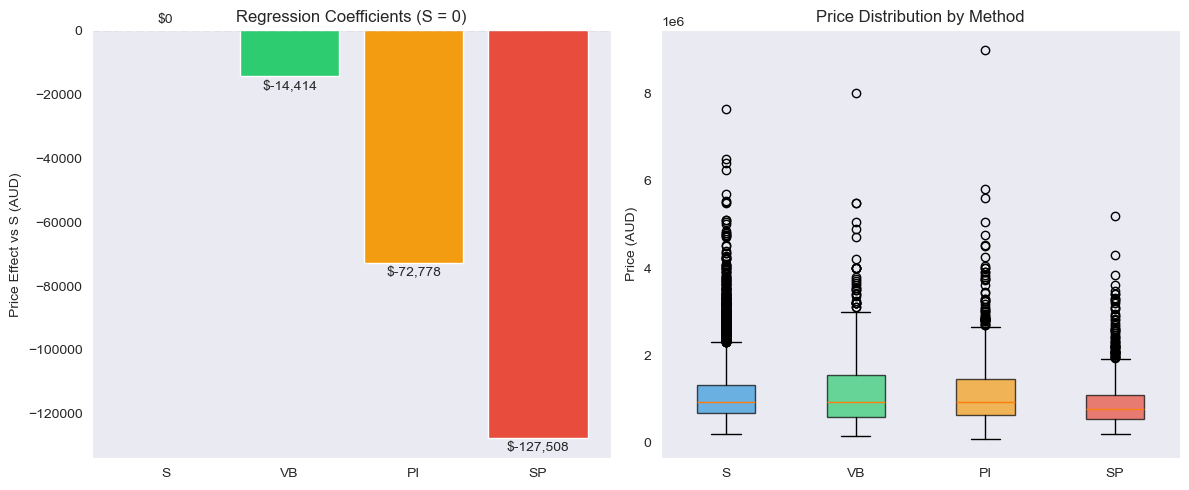

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
method_order = method_coef.index.tolist()
palette = {'S': '#3498db', 'SP': '#e74c3c', 'PI': '#f39c12', 'VB': '#2ecc71'}
bar_colors = [palette[m] for m in method_order]

# ── 1. Regression coefficients ────────────────────────────────────────────
coefs = method_coef['Coefficient']
bars = axes[0].bar(method_order, coefs, color=bar_colors)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set_title('Regression Coefficients (S = 0)')
axes[0].set_ylabel('Price Effect vs S (AUD)')
axes[0].bar_label(bars, fmt='${:,.0f}', padding=3)

# ── 2. Price distribution ─────────────────────────────────────────────────
data_by_method = [df_model.loc[df_model['Method'] == m, 'Price'].values for m in method_order]
bp = axes[1].boxplot(data_by_method, labels=method_order, patch_artist=True)
for patch, m in zip(bp['boxes'], method_order):
    patch.set(facecolor=palette[m], alpha=0.7)
axes[1].set_title('Price Distribution by Method')
axes[1].set_ylabel('Price (AUD)')

plt.tight_layout()
plt.show()

### Insights on Price Variance by Sale Method

All regression coefficients are relative to **S (Sold at auction)** as the baseline.

| Method | Coefficient vs "S" |
|--------|--------------------|
| **S**  | 0 *(baseline)*    |
| **VB** | −26,342           |
| **PI** | −81,532           |
| **SP** | −126,961          |

| Method | Interpretation |
|--------|----------------|
| **S**  | Standard auction sale, the reference point. |
| **VB** | Small negative effect; suggesting weak demand. |
| **PI** | Passed-in properties carry a 82k Loss. The seller's weakened negotiating position after a failed reserve drives the discount. |
| **SP** | Largest discount of all methods at 127k; buyers who close before auction capture a significant price advantage over what competitive bidding would have achieved. |

**Key takeaway:** Every alternative method underperforms a standard auction. The difference scales with how far the sale deviates from open competition — VB remains closest to auction conditions, PI reduce competition, and SP subverts the auction entirely.

In [19]:
# ── 1. Linear Regression ──────────────────────────────────────────────────
# lr already fitted above; evaluate on test set
y_pred_lr = lr.predict(X_test)

print('Linear Regression')
print(f'  R² : {r2_score(y_test, y_pred_lr):.4f}')
print(f'  MAE: ${mean_absolute_error(y_test, y_pred_lr):,.0f}')

Linear Regression
  R² : 0.4657
  MAE: $336,065


### 6. Distance from CBD effect on Price - varied by Suburb and Region

Text(0.5, 1.0, 'Price vs. Distance')

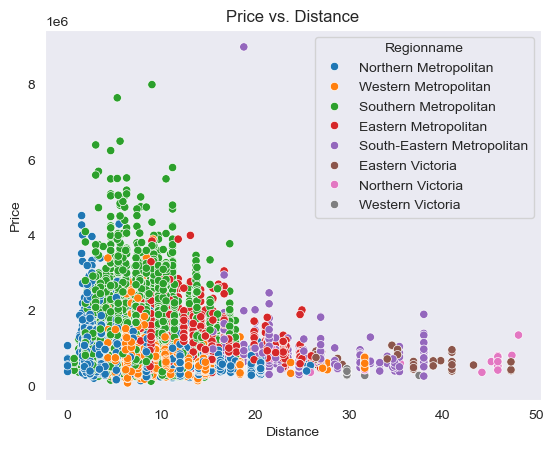

In [20]:
sns.scatterplot(data=df, x='Distance', y='Price',
               hue='Regionname')
plt.title('Price vs. Distance')

**Key observations:**
- Prices generally decrease as distance from CBD increases
- However within the same distance range, prices vary greatly 
  depending on region
- Southern Metropolitan (green) consistently has properties listed with higher 
  prices at similar distances compared to other regions

The scatterplot confirms that distance alone does not explain price. 
Properties at the same distance from the CBD can have very different prices depending on their region. 

Therefore: **Further investigation must be done**

In [21]:
inner_median = df[df['Distance_band'] == 'Inner']['Price'].median()
middle_median = df[df['Distance_band'] == 'Middle']['Price'].median()
outer_median = df[df['Distance_band'] == 'Outer']['Price'].median()

# Create Distance_band with Inner/Middle/Outer labels explicitly
df['Distance_band'] = pd.cut(
    df['Distance'],
    bins=[0, 10, 20, 50],
    labels=['Inner', 'Middle', 'Outer']
)

suburb_scores = df.groupby(
    ['Regionname', 'Distance_band', 'Suburb'], observed=True
)['Price'].median().reset_index()

suburb_scores.columns = ['Regionname', 'Distance_band', 'Suburb', 'Suburb_median']
suburb_scores['Distance_band'] = suburb_scores['Distance_band'].astype(str)

inner_median = df['Price'][df['Distance_band'] == 'Inner'].median()
middle_median = df['Price'][df['Distance_band'] == 'Middle'].median()
outer_median = df['Price'][df['Distance_band'] == 'Outer'].median()

suburb_scores.loc[suburb_scores['Distance_band'] == 'Inner', 'Desirability_Score'] = suburb_scores['Suburb_median'] / inner_median
suburb_scores.loc[suburb_scores['Distance_band'] == 'Middle', 'Desirability_Score'] = suburb_scores['Suburb_median'] / middle_median
suburb_scores.loc[suburb_scores['Distance_band'] == 'Outer', 'Desirability_Score'] = suburb_scores['Suburb_median'] / outer_median

metro_regions = ['Northern Metropolitan', 'Southern Metropolitan',
                 'Eastern Metropolitan', 'Western Metropolitan',
                 'South-Eastern Metropolitan']

suburb_scores_metro = suburb_scores[
    suburb_scores['Regionname'].isin(metro_regions)
].copy()

print(suburb_scores_metro['Distance_band'].unique())
print(suburb_scores_metro['Desirability_Score'].isna().sum())
print(suburb_scores_metro.shape)

top_suburbs = []
for region in metro_regions:
    for band in ['Inner', 'Middle', 'Outer']:
        top = suburb_scores_metro[
            (suburb_scores_metro['Regionname'] == region) &
            (suburb_scores_metro['Distance_band'] == band)
        ].sort_values('Desirability_Score', ascending=False).head(1)
        if not top.empty:
            top_suburbs.append(top)

top_suburbs = pd.concat(top_suburbs)
print(top_suburbs)


['Inner' 'Middle' 'Outer']
0
(292, 5)
                     Regionname Distance_band            Suburb  \
100       Northern Metropolitan         Inner      Princes Hill   
120       Northern Metropolitan        Middle          Oak Park   
128       Northern Metropolitan         Outer         Greenvale   
205       Southern Metropolitan         Inner           Kooyong   
224       Southern Metropolitan        Middle          Brighton   
6          Eastern Metropolitan         Inner      Ivanhoe East   
19         Eastern Metropolitan        Middle         Eaglemont   
54         Eastern Metropolitan         Outer  North Warrandyte   
246        Western Metropolitan         Inner        Aberfeldie   
302        Western Metropolitan        Middle          Seaholme   
317        Western Metropolitan         Outer          Plumpton   
152  South-Eastern Metropolitan        Middle     Wheelers Hill   
176  South-Eastern Metropolitan         Outer          Parkdale   

     Suburb_median  Des

Text(0.5, 1.02, 'Most Desirable Suburb per Distance Band by Region')

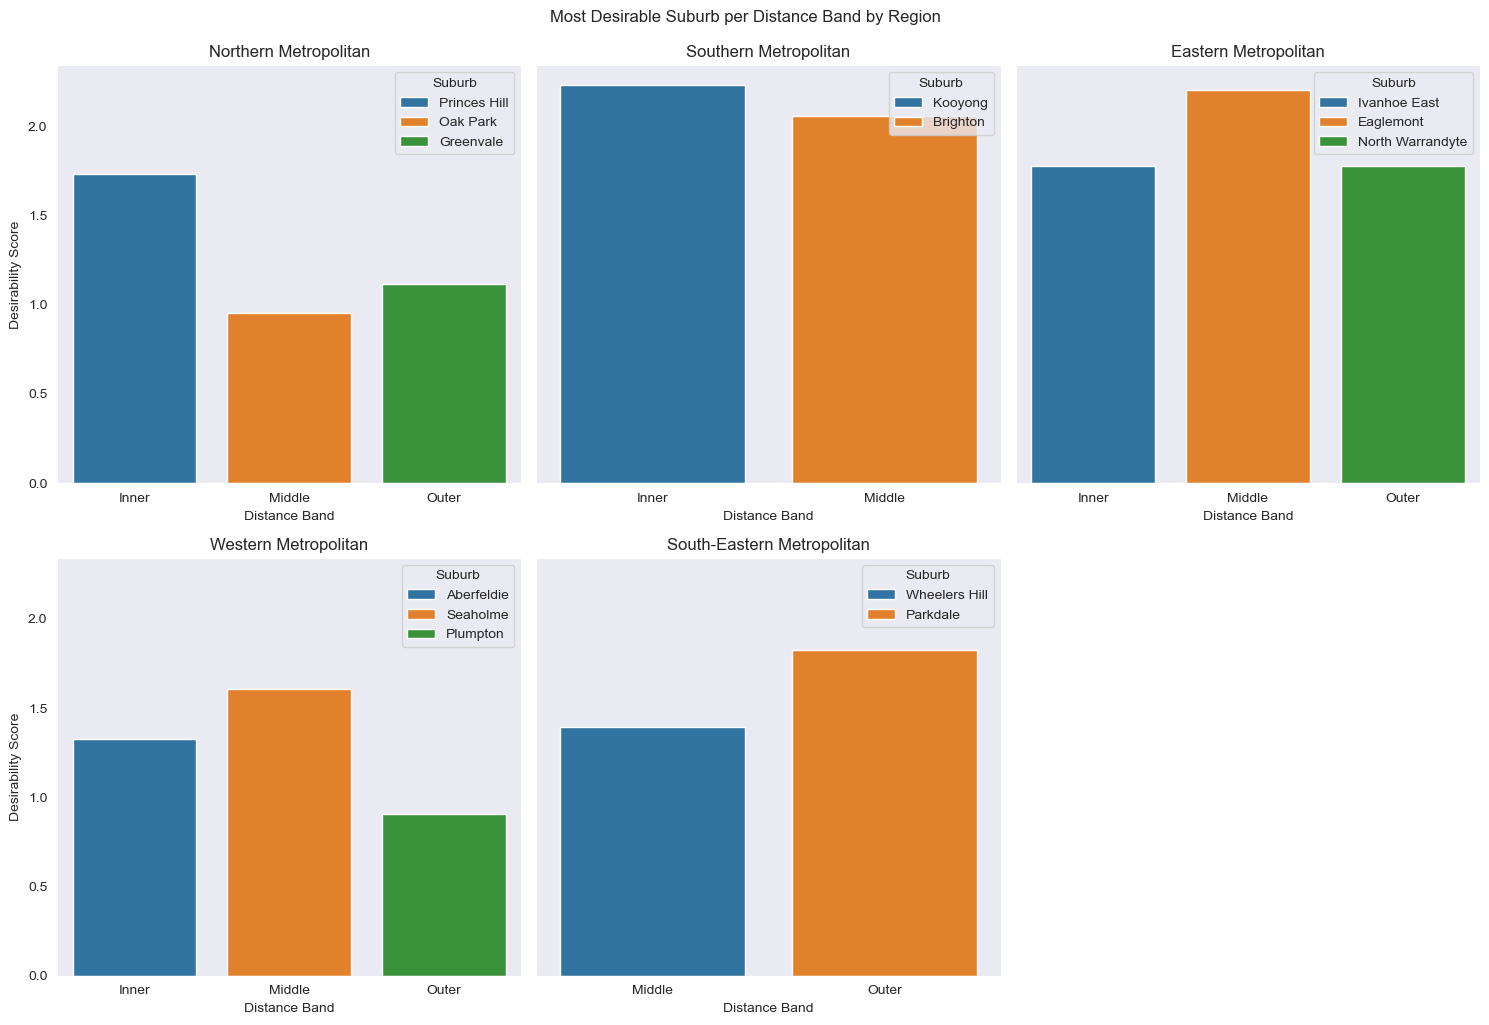

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

regions = ['Northern Metropolitan', 'Southern Metropolitan', 
           'Eastern Metropolitan', 'Western Metropolitan', 
           'South-Eastern Metropolitan']

for i, region in enumerate(regions):
    region_data = top_suburbs[top_suburbs['Regionname'] == region]
    sns.barplot(data=region_data, x='Distance_band', y='Desirability_Score', 
                hue='Suburb', ax=axes[i])
    axes[i].set_title(region)
    axes[i].set_xlabel('Distance Band')
    axes[i].set_ylabel('Desirability Score')

    
axes[5].set_visible(False)
plt.tight_layout()
plt.suptitle('Most Desirable Suburb per Distance Band by Region', y=1.02)

**Desirability Score**
Desirability Score = Suburb_median / Distance_band_median

**Below 1** = cheaper than the average suburb at that distance from CBD

**1** = exactly average for that distance from CBD

**Above 1** = more expensive than the average suburb at that distance from CBD

**Key Findings**
- In Eastern and Western Metropolitan regions, the most desirable 
  suburb falls in the Middle band rather than the Inner band.

This suggests that being closer to the CBD does not always mean higher 
  property prices and suburb reputation within a region matters more 
  than distance alone.

- In South-Eastern Metropolitan, the Outer band has a suburb with a higher desirability score than Middle band.
- In each region, suburb in Inner band (closer to city) does not always have a higher desirability score

This further supports that distance from the CBD does not consistently predict property desirability across all 
  regions

- Northern and Southern Metropolitan follow the expected pattern 
  where Inner band suburbs score highest
- This suggests distance does play a role in these regions, but it does vary by suburb and region

**Note:**
Victorian regions were excluded from the desirability analysis as they have significantly fewer data points compared 
to Metropolitan regions, as seen in the scatterplot. Including them would produce unreliable desirability scores and make 
comparisons unfair.


## 9. Conclusions from EDA

From our exploratory data analysis, we saw how the **"Feature Correlation with Price"** graph revealed that the features that are strongly correlated with price are `Rooms`, `Total_amenities`, and `Is_house`. We chose to exclude `Price_per_room` and `Suburb_median_price` from our analysis as they were both circular with price. Furthermore, `Distance` was the only feature with a notable inverse correlation, confirming that a greater distance from the CBD is associated with lower prices.

The graph of **"Price vs Total Amenities"** showed us that higher total amenity counts were associated with higher median prices, with the line plot showing a general upward trend from around \\$900,000 at 1 amenity to approximately $2,400,000 at 8 amenities. The boxplot reinforced this pattern, showing rising median prices as the total number of amenities increased from 1 to 8. However, there was a wider spread of median prices due to smaller sample sizes towards the upper end.

The graph of **"Price vs Distance"** showed that the property type "House" spanned the full price range and dominated at higher price points across all distances, with the highest concentration of elevated prices within 10km of the CBD. In comparison, the property types "Units" and "Townhouses" clustered tightly at the lower end of the price range regardless of distance, confirming that their proximity to the CBD did not affect their pricing in the same way it did for houses. The concentration of “Units” and “Townhouses” towards to lower end of price range was used when creating type_x_distance

The investigation of the **"Median price of properties by property type"** quantified the type hierarchy directly, showing that houses had a median of \\$1,080,000, townhouses had a median of \\$850,000, and units had a median of $560,000. This told us that houses commanded an estimated 27.5% increase in prices over town houses, and that town houses commanded an estimated 50% increase in price over units. 

The investigation of the **"Median price of properties by number of rooms and property type"** revealed that since the "House" type shows the strongest increase in median price as the number of rooms increases, there is a different valuation of room count depending on the property type. As such, we are able to conclude that using `Is_house` with `Rooms` is justified, as it captures the additional market value associated with houses that is not fully explained by room alone.

Regarding how **method affects the sale price of properties**, the identified coefficients confirm that every method underperforms a standard auction, with SP carrying the largest penalty at \\$127,508 and hence that sale method is a weak predictor of price in isolation. The linear regression achieved an R² of only 0.40 across all features, with method's individual contribution being marginal.

Lastly, the analysis of **"Price vs Distance - varied by Suburb and Region"** shows us that distance from the CBD is not a reliable predictor of price. 
While the heatmap shows a weak negative correlation (-0.16), the scatterplot and desirability subplot reveal that price 
varies significantly by region and suburb at the same distance. This guided the group's decision to focus the desirability 
equation on property-level features like `Rooms`, `Total_amenities` and `Is_house` rather than location. 



To conclude, our findings revealed that `Rooms`, `Total_amenities`, and `Is_house` were the most consistent and intrepretable price-relevant features in the dataset, which we could then use to build our desirability score.

## 10. Modeling / Analysis

### Relative Desirability Score

The desirability score measures **how attractive a property is relative to others in the same suburb**, scored 0–100.

ie. for x amount of amenities and features, where does this property rank within properties in this suburb. 

Emphasis is placed on investigating properties relative to their suburb as suburb-level factors (ie. school zones, proximity to CBD, neighbourhood character) will be captured by location. The score also isolates what makes an individual property stand out *within* its local market.

#### Feature selection

Three features are used, chosen for highest within-suburb correlation with Price and minimal overlap with each other:

**Desirability Score 1:**

| Feature | Within-suburb r | Weight | Reasoning |
|---|---|---|---|
| `Rooms` | 0.48 | **35%** | Highest correlated feature to price and the single biggest driver for price increase.  |
| `Total_amenities` (Bathroom + Car) | 0.37 | **35%** | Captures liveability — bathrooms and parking are consistently valued; complements Rooms without high collinearity (r = 0.60 with Rooms, acceptable) |
| `Is_house` (Type == 'h') | 0.45 | **30%** | Houses command a strong premium over units/townhouses in Melbourne (~25% price increase over townhouses) |



**Desirability Score 2:**

Same rationale as ***Desirabilty Score 1***, but we apply a weightage instead of a binary for `Is_house`.

| Building Type | Percentage |
|---|---|
| 'h' | 1.0 |
| 't' | 0.3 |
| 'u' | 0.0 |

Other notes: `BuildingArea` was excluded despite a strong raw correlation (0.46) because it is missing for ~48% of rows, which would halve the dataset. `Rooms` acts as a reasonable proxy for internal space.

#### Scoring method

For `Rooms` and `Total_amenities`, each property is assigned its **percentile rank within its suburb** (0–1). We look at the relative standing of each property within their suburb (eg. a 4-bedroom house in a suburb where most homes have 2 bedrooms scores higher than the same house in a suburb full of 5-bedroom homes.)

`Is_house` is a binary (1 = house, 0 = unit/townhouse) contributing a flat 20% bonus as reflected by our research on housing type prices.

In [23]:
def pct_rank(x):
    return x.rank(pct=True)

def type_score(t):
    if t == 'h':
        return 1.0
    elif t == 't':
        return 0.3
    else:
        return 0.0

# returns the dataframe with the desirability score calculated
def compute_desirability_score1(dataframe):
    df = dataframe.copy()
    
    # Within-suburb percentile ranks
    df['Rooms_pct']     = df.groupby('Suburb')['Rooms'].transform(pct_rank)
    df['Amenities_pct'] = df.groupby('Suburb')['Total_amenities'].transform(pct_rank)
    
    # Composite score (0–100) 0.45, 0.35,0.2
    df['Desirability_score'] = (
        df['Rooms_pct']     * 0.35 +
        df['Amenities_pct'] * 0.35 +
        df['Is_house']      * 0.30
    ) * 100
    
    return df

# returns the dataframe with the desirability score 2 calculated
def compute_desirability_score2(dataframe):
    df = dataframe.copy()
    
    # Type score: h = 1.0, t = 0.75, u = 0.5
    df['Type_score'] = df['Type'].map(type_score)

    # Within-suburb percentile ranks
    df['Rooms_pct']     = df.groupby('Suburb')['Rooms'].transform(pct_rank)
    df['Amenities_pct'] = df.groupby('Suburb')['Total_amenities'].transform(pct_rank)
    
    # Composite score (0–100)
    df['Desirability_score'] = (
        df['Rooms_pct']     * 0.35 +
        df['Amenities_pct'] * 0.35 +
        df['Type_score']    * 0.30
        
    ) * 100
    
    return df

df_ds1 = compute_desirability_score1(df_2)
df_ds2 = compute_desirability_score2(df_2)

corr = df_ds1[['Desirability_score', 'Price']].corr().loc['Desirability_score', 'Price']
print(f'Desirability score 1 correlation with Price: {corr:.4f}')
corr = df_ds2[['Desirability_score', 'Price']].corr().loc['Desirability_score', 'Price']
print(f'Desirability score 2 correlation with Price: {corr:.4f}')

Desirability score 1 correlation with Price: 0.5280
Desirability score 2 correlation with Price: 0.5315


**Evaluation**

Based on the two methods to calculate desirability score given, we notice the second method gives us a slightly better correlation with price. A 0.5316 correlation proves that there is some statistical significance between our score and price.

We will **use method 2** going forward in our analysis to calculate desirability.


### Implementation of a linear regression model to predict pricing
We perform a linear regression againts price using desirabily score.

Train size: 10,814
Test size:  2,704

── Model Performance ────────────────────
R²:   0.2834
MAE:  $370,226
RMSE: $542,815

Coefficient: 13,883.09
Intercept:   277,114.34
Desirability score 75.0 → predicted price: $1,318,346


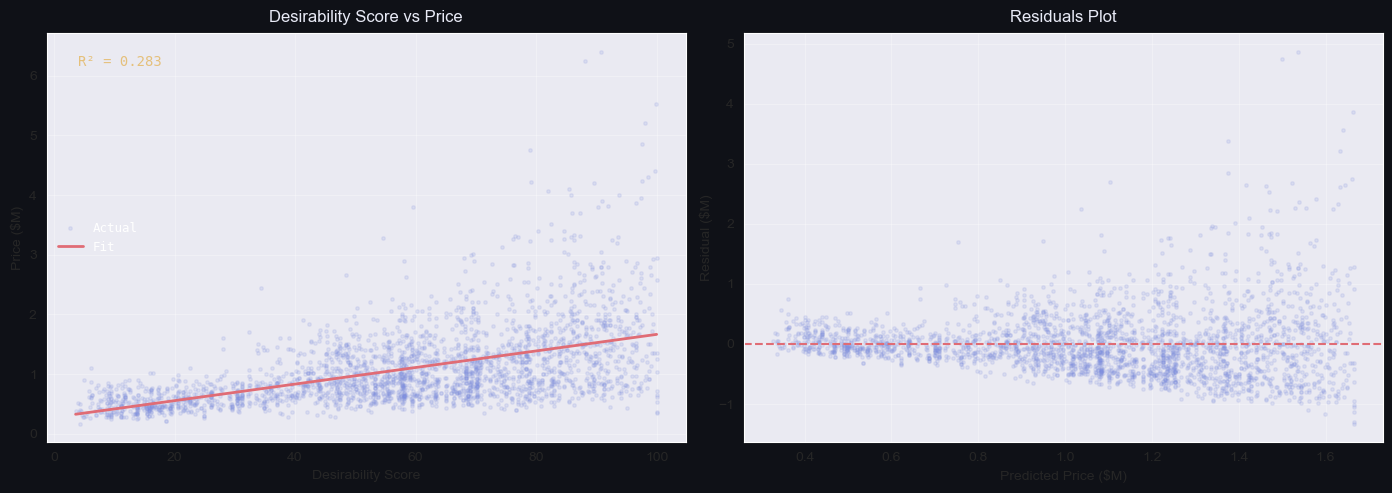

In [24]:
# Train test split (80 training / 20 test)

# ── 1. Compute desirability score ─────────────────────────────────────────
df_model = compute_desirability_score2(df_2)

# ── 2. Drop rows where either feature is null ─────────────────────────────
df_model = df_model[['Desirability_score', 'Price']].dropna()

# ── 3. Define X and y ─────────────────────────────────────────────────────
X = df_model[['Desirability_score']]
y = df_model['Price']

# ── 4. 80/20 train/test split ─────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train size: {len(X_train):,}")
print(f"Test size:  {len(X_test):,}")

# ── 5. Fit model ──────────────────────────────────────────────────────────
model = LinearRegression()
model.fit(X_train, y_train)

# ── 6. Evaluate ───────────────────────────────────────────────────────────
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print(f"\n── Model Performance ────────────────────")
print(f"R²:   {r2:.4f}")
print(f"MAE:  ${mae:,.0f}")
print(f"RMSE: ${rmse:,.0f}")
print(f"\nCoefficient: {model.coef_[0]:,.2f}")
print(f"Intercept:   {model.intercept_:,.2f}")

# ── 7. Predict function ───────────────────────────────────────────────────
def predict_price(desirability_score):
    score = np.array([[desirability_score]])
    prediction = model.predict(score)[0]
    print(f"Desirability score {desirability_score:.1f} → predicted price: ${prediction:,.0f}")
    return prediction

# Example usage
predict_price(75.0)

# ── 8. Plot: predicted vs actual ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='#0f1117')

ACCENT  = '#7b8cde'
ACCENT2 = '#e06c75'
ACCENT4 = '#e5c07b'
MUTED   = '#4a4f6a'

plt.rcParams.update({
    'axes.facecolor': '#1a1d27', 'axes.edgecolor': '#2e3147',
    'axes.labelcolor': '#c8cad8', 'xtick.color': '#6b6f85',
    'ytick.color': '#6b6f85', 'text.color': '#c8cad8',
    'grid.color': '#2e3147', 'grid.linewidth': 0.6,
    'font.family': 'monospace', 'font.size': 9,
})

# Scatter: score vs price with regression line
axes[0].scatter(X_test, y_test/1e6, alpha=0.15, s=6, color=ACCENT, label='Actual')
xs = np.linspace(X_test.min().item(), X_test.max().item(), 100)
axes[0].plot(xs, model.predict(xs.reshape(-1,1))/1e6, color=ACCENT2, lw=2, label='Fit')
axes[0].set_xlabel('Desirability Score')
axes[0].set_ylabel('Price ($M)')
axes[0].set_title('Desirability Score vs Price', fontsize=12, color='#e8eaf6', pad=8)
axes[0].legend(framealpha=0, labelcolor='white')
axes[0].grid(alpha=0.3)
axes[0].text(0.05, 0.92, f'R² = {r2:.3f}', transform=axes[0].transAxes,
             color=ACCENT4, fontsize=10)

# Residuals plot
residuals = y_test - y_pred
axes[1].scatter(y_pred/1e6, residuals/1e6, alpha=0.15, s=6, color=ACCENT3 if False else ACCENT)
axes[1].axhline(0, color=ACCENT2, lw=1.5, ls='--')
axes[1].set_xlabel('Predicted Price ($M)')
axes[1].set_ylabel('Residual ($M)')
axes[1].set_title('Residuals Plot', fontsize=12, color='#e8eaf6', pad=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Train: 10,864  |  Test: 2,716

Selected training suburbs: ['Camberwell', 'Altona']

── TRAIN: Camberwell (n=105)
   R²:   0.7404
   MAE:  $321,190
   RMSE: $462,593

   Coefficient: 27,426.28
   Intercept:   $168,727.26

── TRAIN: Altona (n=57)
   R²:   0.5461
   MAE:  $155,880
   RMSE: $201,104

   Coefficient: 8,141.90
   Intercept:   $404,460.72


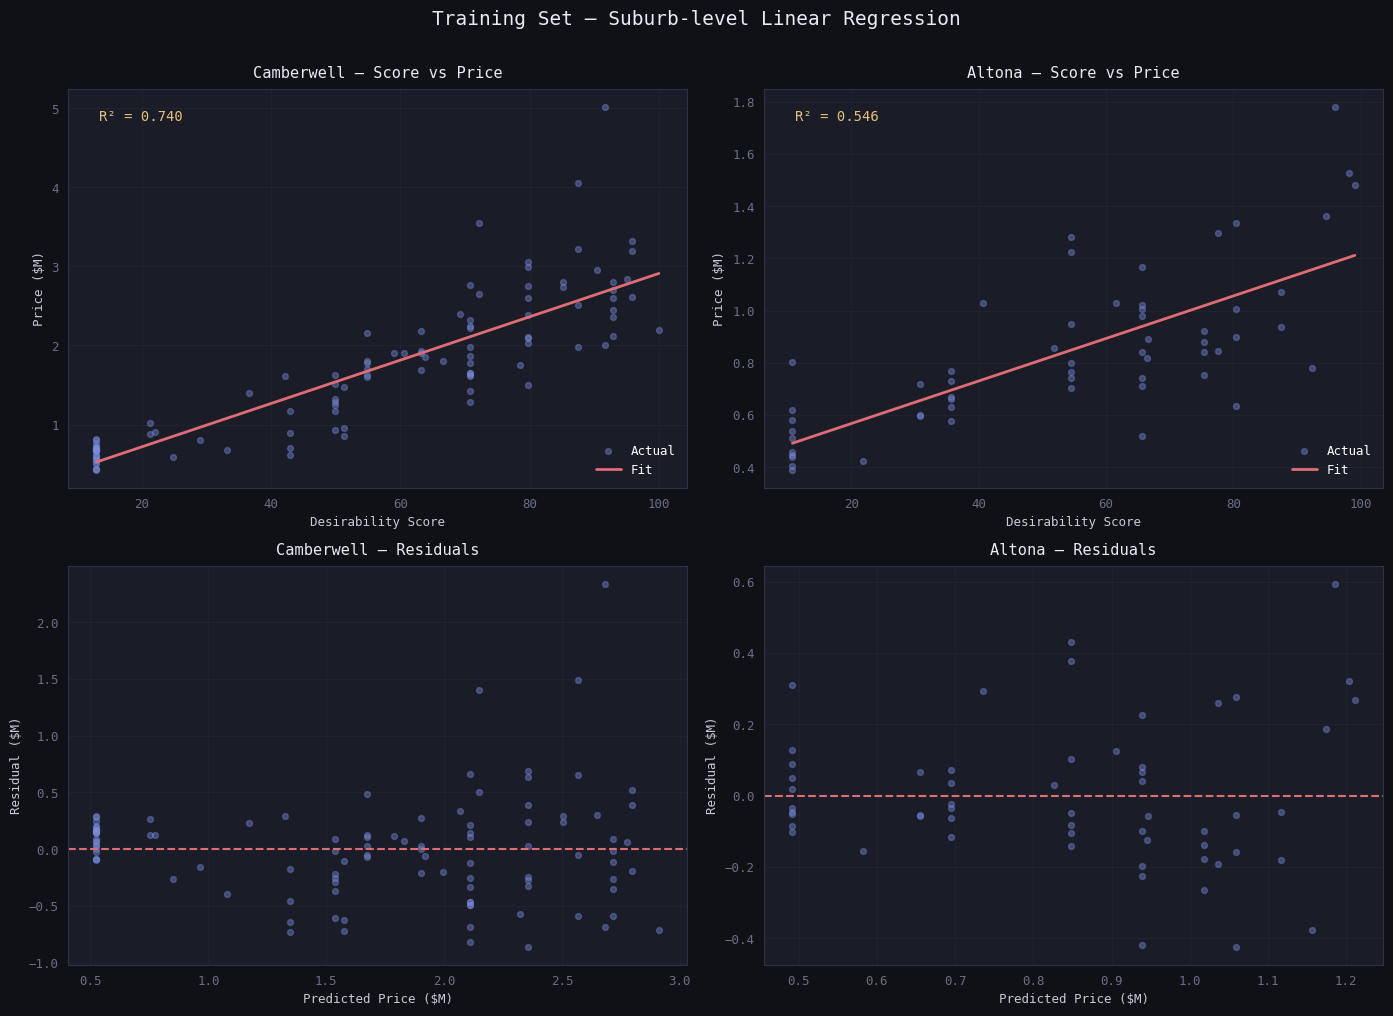


Selected test suburbs: ['Hampton', 'Glen Iris']

── TEST: Hampton (n=34)
   R²:   0.6475
   MAE:  $376,470
   RMSE: $505,821

   Coefficient: 22,927.69
   Intercept:   $254,112.26

── TEST: Glen Iris (n=44)
   R²:   0.7150
   MAE:  $310,341
   RMSE: $424,367

   Coefficient: 23,441.09
   Intercept:   $4,786.92


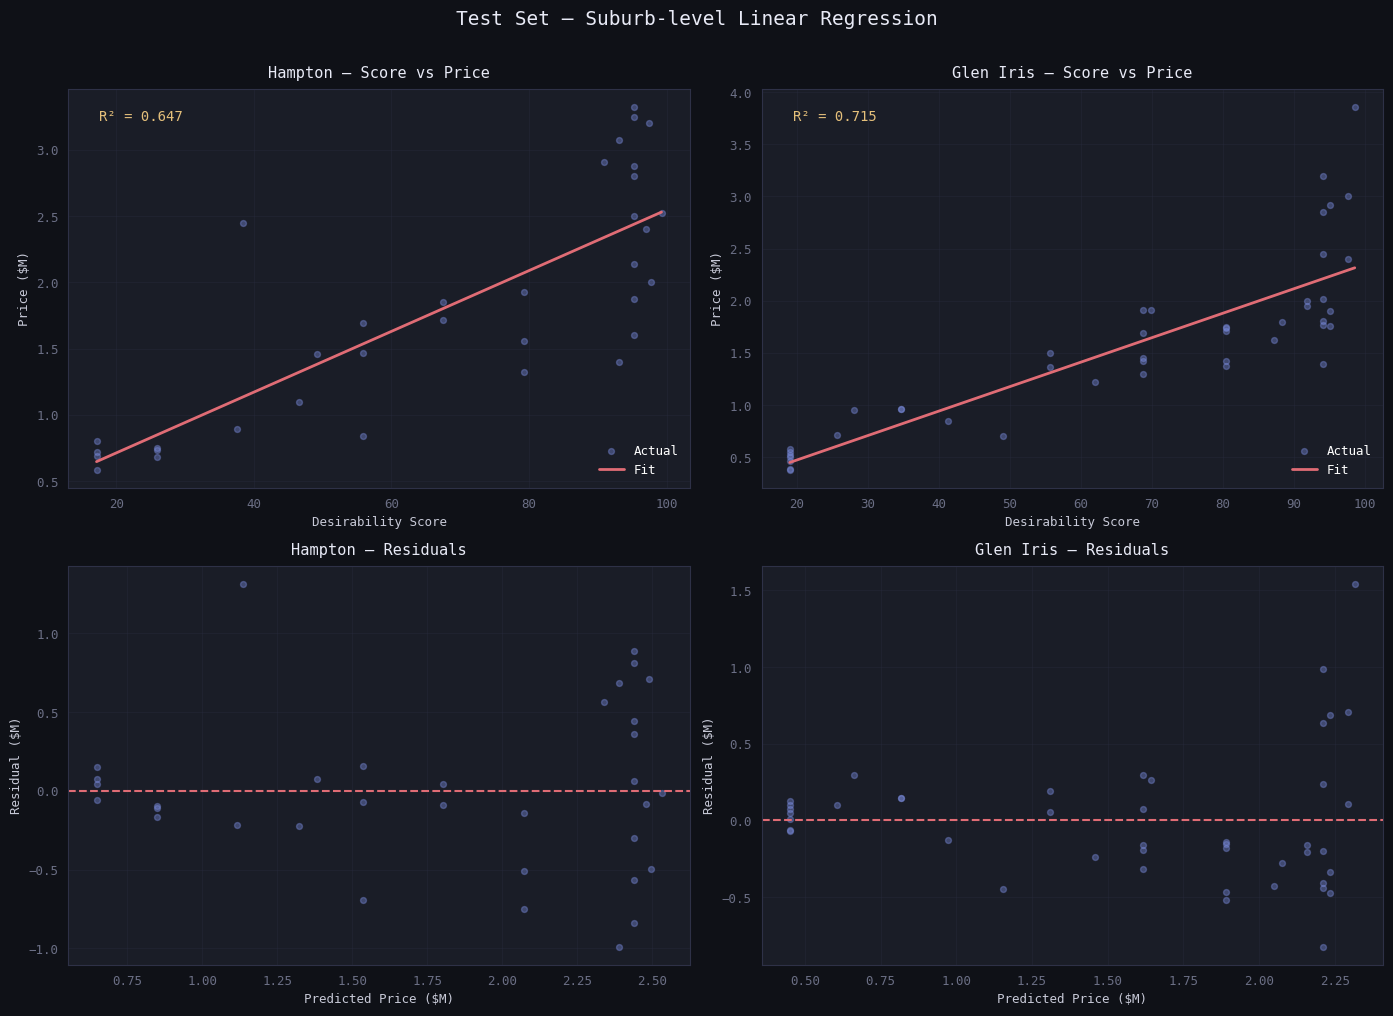

In [25]:
# ── Plot styling ──────────────────────────────────────────────────────────

ACCENT       = '#7b8cde'
ACCENT2      = '#e06c75'
ACCENT4      = '#e5c07b'
DARK_BG      = '#0f1117'
DARK_AX      = '#1a1d27'
MIN_TRAIN_ROWS = 20
MIN_TEST_ROWS  = 20

plt.rcParams.update({
    'axes.facecolor':  DARK_AX,
    'axes.edgecolor':  '#2e3147',
    'axes.labelcolor': '#c8cad8',
    'xtick.color':     '#6b6f85',
    'ytick.color':     '#6b6f85',
    'text.color':      '#c8cad8',
    'grid.color':      '#2e3147',
    'grid.linewidth':  0.6,
    'font.family':     'monospace',
    'font.size':       9,
})


# ─────────────────────────────────────────────────────────────────────────
# HELPER FUNCTIONS
# ─────────────────────────────────────────────────────────────────────────

def score_against_train(test_row, train_df, feature):
    """
    Returns the percentile rank of a test property's feature value
    relative to training properties in the same suburb.
    Falls back to the global training distribution if the suburb
    was not seen during training.
    """
    same_suburb = train_df[train_df['Suburb'] == test_row['Suburb']][feature].dropna()
    reference   = same_suburb if len(same_suburb) > 0 else train_df[feature].dropna()
    return (reference <= test_row[feature]).mean()


def compute_test_desirability(test_df, train_df):
    """
    Computes desirability scores for the test set using the training
    set's suburb distributions to prevent data leakage.
    """
    test_df = test_df.copy()

    test_df['Type_score']    = test_df['Type'].map(type_score)
    test_df['Rooms_pct']     = test_df.apply(score_against_train, axis=1, train_df=train_df, feature='Rooms')
    test_df['Amenities_pct'] = test_df.apply(score_against_train, axis=1, train_df=train_df, feature='Total_amenities')

    test_df['Desirability_score'] = (
        test_df['Rooms_pct']     * 0.35 +
        test_df['Amenities_pct'] * 0.35 +
        test_df['Type_score']    * 0.30
    ) * 100

    return test_df


def get_valid_suburbs(df, min_rows):
    """
    Returns suburbs with enough rows to fit a meaningful regression.
    """
    return [
        suburb for suburb, group in df.groupby('Suburb')
        if group[['Desirability_score', 'Price']].dropna().shape[0] >= min_rows
    ]


def run_suburb_regression(df, suburb, label):
    suburb_df = df[df['Suburb'] == suburb][['Desirability_score', 'Price']].dropna()

    X = suburb_df[['Desirability_score']]
    y = suburb_df['Price']

    model  = LinearRegression().fit(X, y)
    y_pred = model.predict(X)

    r2   = r2_score(y, y_pred)
    mae  = mean_absolute_error(y, y_pred)
    rmse = root_mean_squared_error(y, y_pred)
    coefficient = model.coef_[0]
    intercept   = model.intercept_

    print(f"\n── {label}: {suburb} (n={len(suburb_df)})")
    print(f"   R²:   {r2:.4f}")
    print(f"   MAE:  ${mae:,.0f}")
    print(f"   RMSE: ${rmse:,.0f}")
    print("")
    print(f"   Coefficient: {coefficient:,.2f}")
    print(f"   Intercept:   ${intercept:,.2f}")

    return suburb, model, X, y, y_pred, r2


def plot_suburb_pair(results, suptitle):
    """
    Plots score vs price and residuals for 2 suburbs side by side.
    Top row:    Desirability Score vs Price with regression line
    Bottom row: Residuals vs Predicted Price
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor=DARK_BG)
    fig.suptitle(suptitle, fontsize=14, color='#e8eaf6', fontfamily='monospace', y=1.01)

    for col, (suburb, model, X, y, y_pred, r2) in enumerate(results):

        residuals = y - y_pred
        xs        = np.linspace(X['Desirability_score'].min(),
                                X['Desirability_score'].max(), 200).reshape(-1, 1)

        # ── Score vs price ────────────────────────────────────────────────
        ax_top = axes[0, col]
        ax_top.scatter(X, y / 1e6, alpha=0.4, s=18, color=ACCENT,  label='Actual')
        ax_top.plot(xs, model.predict(xs) / 1e6,   color=ACCENT2, lw=2, label='Fit')
        ax_top.set_xlabel('Desirability Score')
        ax_top.set_ylabel('Price ($M)')
        ax_top.set_title(f'{suburb} — Score vs Price', fontsize=11, color='#e8eaf6', pad=8)
        ax_top.text(0.05, 0.92, f'R² = {r2:.3f}', transform=ax_top.transAxes, color=ACCENT4, fontsize=10)
        ax_top.legend(framealpha=0, labelcolor='white')
        ax_top.grid(alpha=0.3)

        # ── Residuals ─────────────────────────────────────────────────────
        ax_bot = axes[1, col]
        ax_bot.scatter(y_pred / 1e6, residuals / 1e6, alpha=0.4, s=18, color=ACCENT)
        ax_bot.axhline(0, color=ACCENT2, lw=1.5, ls='--')
        ax_bot.set_xlabel('Predicted Price ($M)')
        ax_bot.set_ylabel('Residual ($M)')
        ax_bot.set_title(f'{suburb} — Residuals', fontsize=11, color='#e8eaf6', pad=8)
        ax_bot.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ─────────────────────────────────────────────────────────────────────────
# PIPELINE
# ─────────────────────────────────────────────────────────────────────────

random.seed(42)

# ── 1. Train / test split ─────────────────────────────────────────────────
train_df, test_df = train_test_split(df_2, test_size=0.2, random_state=42)
print(f"Train: {len(train_df):,}  |  Test: {len(test_df):,}")

# ── 2. Score the training set (within-suburb percentile ranks) ────────────
train_df = compute_desirability_score2(train_df)

# ── 3. Score the test set (anchored to training distributions) ────────────
test_df = compute_test_desirability(test_df, train_df)

# ── 4. Train suburbs — sample and regress ────────────────────────────────
selected_train_suburbs = random.sample(get_valid_suburbs(train_df, MIN_TRAIN_ROWS), 2)
print(f"\nSelected training suburbs: {selected_train_suburbs}")

train_results = [run_suburb_regression(train_df, suburb, 'TRAIN')
                 for suburb in selected_train_suburbs]

plot_suburb_pair(train_results, 'Training Set — Suburb-level Linear Regression')

# ── 5. Test suburbs — sample and regress ─────────────────────────────────
selected_test_suburbs = random.sample(get_valid_suburbs(test_df, MIN_TEST_ROWS), 2)
print(f"\nSelected test suburbs: {selected_test_suburbs}")

test_results = [run_suburb_regression(test_df, suburb, 'TEST')
                for suburb in selected_test_suburbs]

plot_suburb_pair(test_results, 'Test Set — Suburb-level Linear Regression')

## Note
***Due to the nature of the random selection of the training and testing suburbs, the results below are for when our 2 selections were 'Glen Iris' and 'Essedon'.***

#### Evaluating our score at a suburb level

An R^2 of **0.6832** and **0.7414**, a much better value compared to the R^2 of the regression against the entire Melbourne dataset. 

We get an MAE of **327,583** and **220,972**, slightly better predictions 

## 11. Model / Analysis Conclusions

| Feature | Melbourne | Suburb | Evaluation |
|---|---|---|---|
| **R^2** | 0.2831 | 0.6832 & 0.7414 | R^2 roughly doubles confirming the score is a stronger predictor within a suburb than across all of Melbourne. |
| **Mean Absolute Error** | 367,008 | 327,583 & 220,972 | Suburb-level predictions are closer to actual prices.|
| **Root Mean Squared Error** | 554,105 | 425,171 & 292,918 | The gap between MAE and RMSE narrows at suburb level, meaning fewer extreme mispredictions.|
| **Coefficient** | 13,785.36 | 26,779.57 & 16,899.12 | price-per-point varies in one suburb versus the other, implying 1 desirability point gain means more in dollar terms in higher-value suburbs. |
| **Intercept** | 282,716.49 | -170,433.19 & 48,054.04 | Negative price should not be interpreted as a price floor.|


#### Evaluation of Model Results

We obtained very different and interesting results when we regress our score against the entire Melbourne dataset versus at a suburb level. However one fact remains constant, the model performed much better when the dataset was subsetted by suburbs. 

**R^2 Score**

For the Melbourne model, we got an R^2 of **0.2820**, which we believe is expected of a single-feature linear regression model. This score greatly improved to **0.6832** and **0.7414** after subsetting, consistent with our expectation and nature of our score. 

**Mean Absolute Error & Root Mean Squared Error**

For the Melbourne model, we got an MAE of **369,649** which implies on average our predictions are off by that amount and an RMSE of **554,555** implies that there could be significant outliers dragging the predicted price upwards. This makes sense as there can a big difference in price between two properties with the same desirability scores but from different suburbs. 

At a suburb level, MAE drops to **327,582** and **220,972** and RMSE drops to **425,171** and **292,918** which shows an improvement the accuracy of predicted prices and less significant outliers. The clear "funnel" shape shown in the residual plot of the Melbourne model is also reduced in the suburb level, showing lesser variance in price. 

**Coefficient & Intercept**

For the Melbourne model, the coefficient of **13,785** shows that for each 1.0 increase in desirability score, our price increases by $13,785 globally with a baseline of **282,716**. At the suburb level, this coefficient can vary quite significantly, **26,779** for a higher value suburb vs **16,899** for a lower one. 

**The two selected suburbs are 'Glen Iris' and 'Essedon'.**

#### Limitations

* Limited feature dataset - The score uses only rooms, total_amenitites and housing type as we believe the scope of the data is quite narrow for an accurate prediction of pricing. Factors that heavily influence price such as proximity to schools, public transport, crime rates for example were not provided. Other useful information like `BuildingArea` to calculate price per sqm was also not provided. 

* Small and outdated dataset - This dataset consist of data from 2017-2018 and has very few rows of data. This resulted in some suburbs only having 10-15 properties which leads to statistically weak regressions and unreliable predictions. Additionally, results from a 10 year old dataset will not be reliable in today's market. 

* Arbitrary weights - The 0.35 / 0.35 / 0.30 weighting was manually assigned and tweaked according to our individual estimates and reasoning for what we believed is a correct weightage. Ideally some statistical justification should be used.

* Less accurate predictions as prices increase - Observing the residual plots in both the Melbourne and suburb model we observe that it follows a "funnel" shape which is tighter on the left and wider at the right end. This implies that our model is able to predict cheap properties well, but becomes less reliable as prices increases.


#### Potential Improvements

* Addition of other uncorrelated features - Incorporation of price per sqm, proximity to public transport and malls, crime rates and school zones will boost the accuracy and prediction power of our score.

* Data-driven weights - Perhaps using regression or other statistical methods to determine optimal feature weights on the training set rather than manually assigning them.

## 12. Overall Conclusions

Answer your research questions based on findings. Summarise key insights, implications, and possible next steps.

This project set out to answer: **What makes a property desirable in Melbourne's housing market?**

Our EDA identified `room count`, `total amenities` (`bathrooms` and car spaces), and `property type` as the three strongest and most interpretable predictors of price, with `distance` from the CBD serving as the only notable inverse correlation. 

Using these three features (`rooms`, `total_amenities`, `property_type`), we created a desirability score that ranks each property relative to others within its own suburb, deliberately isolating individual property quality from suburb-level location effects.

The score achieved a correlation of **0.53** with price across all of Melbourne, and when the regression was applied at the suburb level, R² improved substantially from **0.28** to as high as **0.74**, suggesting that property-level features are meaningfully predictive of price within a local market context. 

For buyers, a high-scoring property in a suburb where most homes have fewer rooms and fewer amenities represents genuine relative value worth investigating further. For sellers, the score provides a concrete benchmark for pricing a listing against local competition. Future iterations of this model would benefit from incorporating external data such as proximity to schools, public transport, and crime statistics, alongside a data-driven approach to feature weighting rather than the manually assigned weights used here, both of which would address the primary limitations of the current methodology.

## 13. References

List sources, datasets, and literature cited in your report.

Dataset source: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot
